<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/JS07/JS07_TUGAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA : HAFIZ RIZQI HERNANDA
# NIM : 244107040154
# KELAS : TI-3C


#✏️Tugas Lab
Klasterisasi Data Nasabah Kartu Kredit

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

2. buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

5. Tentukan jumlah k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

Langkah 0 - Downnload Dataset

In [1]:
from google.colab import files
uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


Langkah 1 - Import Library

In [2]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

Langkah 2 - Load dan Inspeksi Data

Memuat data CC_Customer_Dataset.csv ke dalam dataframe, kemudian melakukan inspeksi pada 5 baris data pertama:

In [3]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Lakukan inspeksi profil data untuk mengecek tipe data dan missing values:

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


Didapatkan informasi bahwa terdapat 660 data dan tidak ada missing values pada seluruh variabel.

#Langkah 3 - Seleksi Fitur & Plotting (Soal 1)
Soal 1: Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_Credit_Cards. Apakah sebaran data dapat dikatakan linier?

Melakukan proses seleksi fitur (slicing) untuk mengambil dua variabel yang diminta, yaitu Avg_Credit_Limit dan Total_Credit_Cards:

In [5]:
# Features Selection (2 Variabel)
X_2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
print(X_2.head())

   Avg_Credit_Limit  Total_Credit_Cards
0            100000                   2
1             50000                   3
2             50000                   7
3             30000                   5
4            100000                   6


Selanjutnya, lakukan proses plotting menggunakan scatterplot untuk melihat sebaran data berdasarkan kedua fitur tersebut:

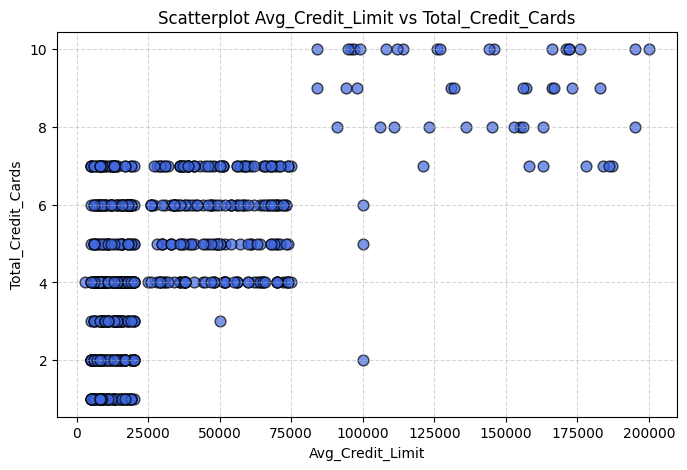

In [6]:
# Make a scatterplot using Avg_Credit_Limit and Total_Credit_Cards
plt.figure(figsize=(8, 5))
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.scatter(X_2.iloc[:, 0], X_2.iloc[:, 1], s=60, alpha=0.7, color='royalblue', edgecolors='k')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Hasil Analisis Soal Nomor 1:
Jika diamati secara visual dalam konteks pemisahan klaster (linear separability): Ya, sebaran klaster data dapat dipisahkan secara linier. Terlihat terdapat 3 kelompok (cluster) data yang terpisah dengan baik menggunakan batas garis lurus imajiner (kelompok limit rendah $\le 20.000$ di sebelah kiri, kelompok limit menengah $25.000 - 75.000$ di bagian tengah, dan kelompok limit tinggi $> 80.000$ di bagian kanan atas).

Jika ditinjau dari bentuk korelasi regresi linier: Titik-titik data tidak membentuk satu garis lurus tunggal yang kontinu, melainkan terbagi menjadi gugusan bertingkat, walaupun secara umum memiliki kecenderungan positif (semakin besar Avg_Credit_Limit, semakin banyak Total_Credit_Cards yang dimiliki).

#Langkah 4 - Menentukan $k$ Terbaik dengan Elbow Method pada K-Means (Soal 2)
Soal 2: Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah $k$ yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

Cara kerja Elbow Method adalah mengevaluasi nilai Sum of Squared Errors (SSE) melalui properti inertia_ untuk setiap nilai $k$ pada rentang $1$ hingga $9$, kemudian memvisualisasikannya dengan linechart:

k=1 -> Nilai SSE: 932931365218.19
k=2 -> Nilai SSE: 315872383980.64
k=3 -> Nilai SSE: 93831368689.85
k=4 -> Nilai SSE: 53044221929.51
k=5 -> Nilai SSE: 30884746200.31
k=6 -> Nilai SSE: 23676885595.56
k=7 -> Nilai SSE: 17506496809.03
k=8 -> Nilai SSE: 12571260834.21
k=9 -> Nilai SSE: 9552287379.14


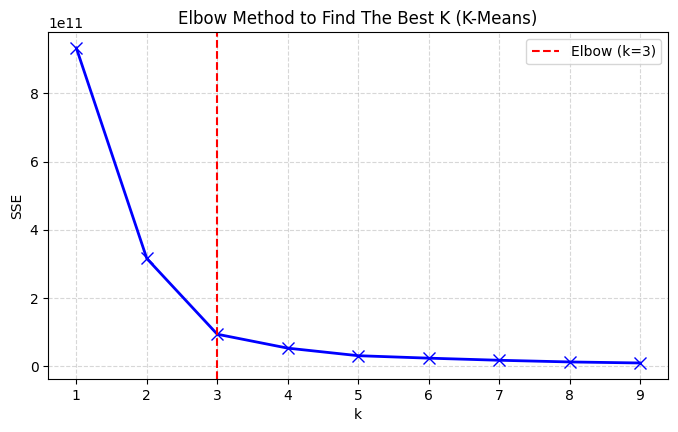

In [7]:
# Find the best k using Elbow Method
sse = []

# Build k range from 1 to 9
K = range(1, 10)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeanModel.fit(X_2)
    sse.append(kmeanModel.inertia_)
    print(f'k={k} -> Nilai SSE: {kmeanModel.inertia_:.2f}')

# Plotting the distortions
plt.figure(figsize=(8, 4.5))
plt.plot(K, sse, "bx-", linewidth=2, markersize=8)
plt.axvline(x=3, color='red', linestyle='--', label='Elbow (k=3)')
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K (K-Means)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Hasil Analisis Soal Nomor 2:
Berdasarkan grafik linechart SSE untuk setiap nilai $k$, nilai $k$ terbaik yang dipilih adalah $k = 3$.
   
Mengapa memilih $k = 3$? Jumlah klaster terbaik tidak dipilih semata-mata karena nilai SSE paling rendah (sebab nilai SSE pasti terus mengecil seiring bertambahnya jumlah $k$), melainkan dicari pada posisi di mana nilai SSE turun dengan sangat tajam kemudian diikuti oleh penurunan yang lebih landai/stabil (posisi elbow/siku).   

Pada grafik terlihat bahwa dari $k=1$ ke $k=2$ dan dari $k=2$ ke $k=3$, garis SSE mengalami penurunan yang sangat curam (dari 932,93 Miliar turun ke 315,87 Miliar, lalu turun tajam ke 93,83 Miliar). Setelah melewati titik $k = 3$ (menuju $k = 4, 5, \text{dst.}$), grafik mulai melandai, sehingga $k = 3$ adalah jumlah klaster paling optimal.

#Langkah 5 - Membuat Model K-Means & Visualisasi Scatterplot (Soal 3)
Soal 3: Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

Setelah mendapatkan nilai optimal $k = 3$, kita latih model K-Means menggunakan fit_predict() dan memvisualisasikan sebaran klaster beserta titik pusatnya (centroid) menggunakan scatterplot:

Nilai SSE K-Means (k=3): 93831368689.85272
Nilai Silhouette Score K-Means (k=3): 0.7187201698623006


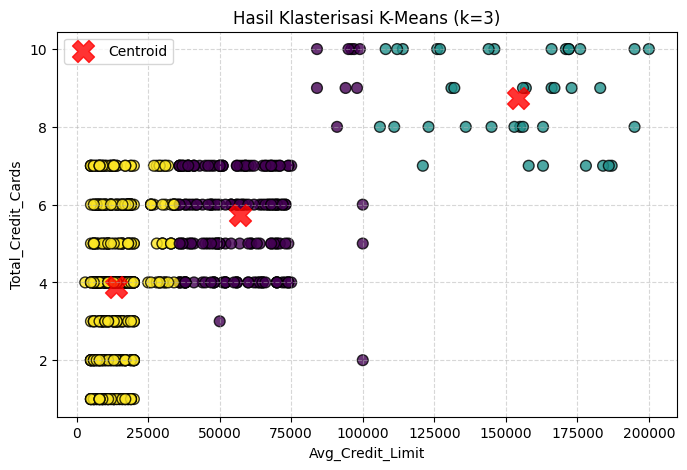

In [8]:
# Initiate K-Means object with number of cluster is 3
cl_kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X_2)

# Print SSE & Silhouette Score
print(f'Nilai SSE K-Means (k=3): {cl_kmeans.inertia_}')
print(f'Nilai Silhouette Score K-Means (k=3): {silhouette_score(X_2, y_kmeans)}')

# Plot the clustering result
plt.figure(figsize=(8, 5))
plt.scatter(X_2.iloc[:, 0], X_2.iloc[:, 1], s=60, c=y_kmeans, cmap='viridis', alpha=0.8, edgecolors='k')

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.8, marker='X', label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Terlihat pada scatterplot bahwa ketiga klaster terpisah dengan rapi bersama titik centroid merah di tengah masing-masing klaster, dengan nilai Silhouette Score yang sangat baik sebesar 0,7187.

#Langkah 6 - Klasterisasi dengan DBSCAN Menggunakan Seluruh Variabel (Soal 4)
Soal 4: Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

Pada tahap seleksi fitur untuk seluruh variabel, kolom Sl_No (indeks nomor urut) dan Customer Key (kode unik pelanggan) tidak digunakan karena bukan merupakan fitur numerik yang merepresentasikan perilaku pelanggan. Dengan demikian, digunakan index slicing df.iloc[:, 2:] yang mengambil 5 variabel: Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made.

Karena algoritma DBSCAN bekerja berdasarkan kepadatan jarak dan sangat sensitif terhadap parameter epsilon (eps), maka kelima fitur distandarisasi terlebih dahulu menggunakan StandardScaler agar perbedaan skala ribuan pada Avg_Credit_Limit tidak mendominasi fitur lainnya:

   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  
0                    1                 0  
1                   10                 9  
2                    3                 4  
3                    1                 4  
4                   12                 3  
Label klaster yang terbentuk: [-1, 0, 1, 2]
Jumlah anggota tiap klaster:
  0    608
-1     27
 1     16
 2      9
Name: count, dtype: int64


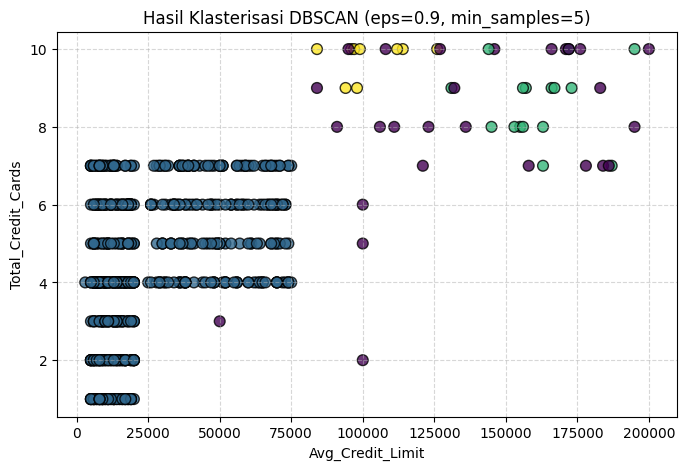

In [11]:
# Seleksi seluruh variabel yang dapat digunakan (tanpa Sl_No dan Customer Key)
X_all = df.iloc[:, 2:]
print(X_all.head())

# Standarisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_all_scaled = scaler.fit_transform(X_all)

# Melakukan klasterisasi dengan DBSCAN
dbscan = DBSCAN(eps=0.9, min_samples=5)
cluster_db = dbscan.fit_predict(X_all_scaled)

print('Label klaster yang terbentuk:', pd.Series(cluster_db).unique().tolist())
print('Jumlah anggota tiap klaster:\n', pd.Series(cluster_db).value_counts())

# Plotting hasil klasterisasi DBSCAN pada scatterplot
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=cluster_db, s=60, cmap='viridis', alpha=0.8, edgecolors='k')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi DBSCAN (eps=0.9, min_samples=5)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Model DBSCAN berhasil mengelompokkan data ke dalam 3 klaster utama (klaster 0, 1, dan 2) serta mengidentifikasi 27 titik data noise / outlier (dilabeli -1).

#Langkah 7 - Menentukan Nilai Terbaik dengan Elbow Method pada Seluruh Variabel (Soal 5)

Soal 5: Tentukan jumlah $k$ yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

Ketika menggunakan seluruh variabel yang telah distandarisasi (X_all_scaled), metode Elbow dapat diterapkan untuk:
1. Menentukan jumlah klaster ($k$) terbaik berdasarkan nilai SSE pada kelima variabel.   
2. Menentukan nilai radius epsilon (eps) terbaik pada DBSCAN menggunakan grafik jarak tetangga terdekat (K-Distance Graph)

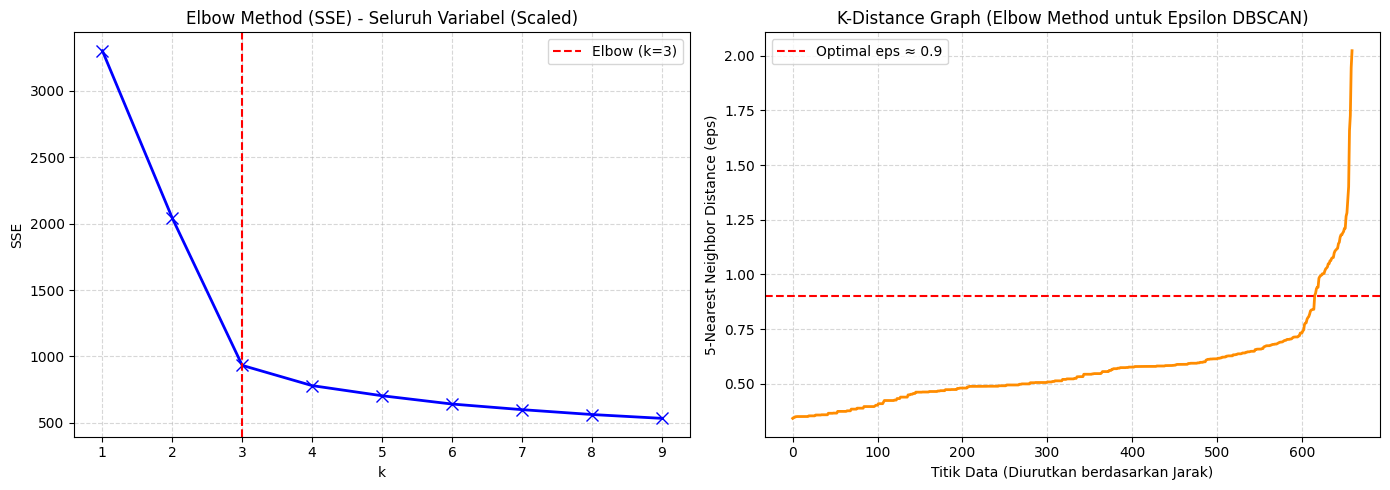

In [12]:
# 1. Elbow Method (SSE) pada seluruh variabel yang dapat digunakan (5 variabel terstandarisasi)
sse_all = []
K = range(1, 10)
for k in K:
    km_all = KMeans(n_clusters=k, random_state=0, n_init=10)
    km_all.fit(X_all_scaled)
    sse_all.append(km_all.inertia_)

# 2. K-Distance Graph (Elbow Method untuk menentukan nilai epsilon terbaik pada DBSCAN)
neigh = NearestNeighbors(n_neighbors=5)
nbrs = neigh.fit(X_all_scaled)
distances, indices = nbrs.kneighbors(X_all_scaled)
distances_sorted = np.sort(distances[:, 4], axis=0)

# Plotting kedua grafik Elbow Method
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(K, sse_all, 'bx-', linewidth=2, markersize=8)
ax[0].axvline(x=3, color='red', linestyle='--', label='Elbow (k=3)')
ax[0].set_title('Elbow Method (SSE) - Seluruh Variabel (Scaled)')
ax[0].set_xlabel('k')
ax[0].set_ylabel('SSE')
ax[0].legend()
ax[0].grid(True, linestyle='--', alpha=0.5)

ax[1].plot(distances_sorted, color='darkorange', linewidth=2)
ax[1].axhline(y=0.9, color='red', linestyle='--', label='Optimal eps ≈ 0.9')
ax[1].set_title('K-Distance Graph (Elbow Method untuk Epsilon DBSCAN)')
ax[1].set_xlabel('Titik Data (Diurutkan berdasarkan Jarak)')
ax[1].set_ylabel('5-Nearest Neighbor Distance (eps)')
ax[1].legend()
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#Hasil Analisis Soal Nomor 5:
Pemilihan Nilai $k = 3$ (Seluruh Variabel): Pada grafik kiri (Elbow Method SSE), nilai SSE turun secara tajam dari $k=1$ (3300,00) ke $k=2$ (2040,99), kemudian mengalami penurunan tajam terakhir pada titik $k=3$ (933,04). Setelah titik $k=3$ (menuju $k=4$ dengan SSE 780,77 hingga $k=9$ dengan SSE 534,62), grafik bergerak melandai dan stabil. Hal ini membuktikan bahwa pada seluruh variabel terdapat 3 klaster pelanggan utama (pelanggan pengguna telepon berlimit rendah, pelanggan pengunjung bank berlimit menengah, dan pelanggan pengguna online berlimit tinggi).   

Pemilihan Nilai eps = 0.9 (K-Distance Graph DBSCAN): Pada grafik kanan, titik siku (elbow) sebelum kurva jarak melonjak tajam ke atas berada di rentang 0,7 hingga 0,9. Pemilihan nilai eps = 0.9 pada min_samples = 5 secara konsisten membentuk 3 klaster utama dengan rasio noise yang terkendali.

#Langkah 8 - Evaluasi Model DBSCAN dengan Silhouette Score & DBI (Soal 6)
Soal 6: Tentukan nilai silhouette score dan DBI dari model DBSCAN.

Melakukan evaluasi performa hasil klasterisasi DBSCAN menggunakan metrik Silhouette Score dan Davies-Bouldin Index (DBI)

In [13]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Compute and print Silhouette Score
print(f"Silhouette Score: {silhouette_score(X_all_scaled, cluster_db)}")

# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X_all_scaled, cluster_db)
print(f"Davies-Bouldin Index: {db}")

Silhouette Score: 0.4645014431416295
Davies-Bouldin Index: 1.942033774109667


#Hasil Analisis Soal Nomor 6:
Silhouette Score: Model DBSCAN menghasilkan nilai sebesar 0,4645. Nilai positif yang mendekati 0,5 ini menunjukkan struktur klaster yang cukup baik, mengingat Silhouette Coefficient juga menghitung titik-titik noise (-1) sebagai satu kelompok tersendiri sehingga nilainya cenderung lebih rendah dibandingkan K-Means.   

Davies-Bouldin Index (DBI): Model DBSCAN menghasilkan nilai DBI sebesar 1,9420 (semakin kecil nilai DBI mendekati 0, semakin baik tingkat separasi antar klaster).